<a href="https://colab.research.google.com/github/EdsonpAl/Projeto_Analise_Hotel_Booking/blob/main/Projeto_Analise_Hotel_Bookings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

df = pd.read_csv("hotel_bookings.csv")

df.shape


(119390, 32)

In [ ]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:
df.isnull().sum().sort_values(ascending=False).head(10)

,0
company,112593
agent,16340
country,488
children,4
arrival_date_month,0
arrival_date_week_number,0
hotel,0
is_canceled,0
stays_in_weekend_nights,0
arrival_date_day_of_month,0


In [ ]:
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")

df = df.drop(columns=["company", "agent"])

df.isnull().sum().sort_values(ascending=False).head(10)

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


In [ ]:
duplicados = df.duplicated().sum()

print("Quantidade de registros duplicados:", duplicados)

Quantidade de registros duplicados: 32020


Tratamento de registros duplicados:
Foram identificados 32.020 registros com valores duplicados. Como a base de dados não possui um identificador único para cada reserva, registros com características iguais podem corresponder a reservas distintas. Por esse motivo, optou-se por não excluir automaticamente esses registros, evitando a remoção de dados potencialmente válidos.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 30 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119390 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [ ]:
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" +
    df["arrival_date_month"] + "-" +
    df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d",
    errors="coerce"
)

print("Tipo da nova coluna:")
print(df["arrival_date"].dtype)

print("\nPrimeiras datas:")
print(df["arrival_date"].head())

Tipo da nova coluna:
datetime64[ns]

Primeiras datas:
0   2015-07-01
1   2015-07-01
2   2015-07-01
3   2015-07-01
4   2015-07-01
Name: arrival_date, dtype: datetime64[ns]


In [ ]:
Q1 = df["lead_time"].quantile(0.25)
Q3 = df["lead_time"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers_lead_time = df[
    (df["lead_time"] < limite_inferior) |
    (df["lead_time"] > limite_superior)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Limite inferior:", limite_inferior)
print("Limite superior:", limite_superior)
print("Quantidade de possíveis outliers:", len(outliers_lead_time))

Q1: 18.0
Q3: 160.0
IQR: 142.0
Limite inferior: -195.0
Limite superior: 373.0
Quantidade de possíveis outliers: 3005


Tratamento de possíveis outliers: Foram identificados 3.005 possíveis outliers na variável lead_time pelo método IQR. Como esses valores representam reservas realizadas com grande antecedência e são valores possíveis no contexto do dataset, optou-se por mantê-los na análise, evitando a exclusão de observações potencialmente válidas.

In [ ]:
reservas_canceladas = df[df["is_canceled"] == 1]

print("Quantidade de reservas canceladas:", len(reservas_canceladas))
reservas_canceladas.head()

Quantidade de reservas canceladas: 44224


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date,total_nights,total_guests,has_car_parking,has_previous_booking,faixa_lead_time
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,...,0,1,Canceled,2015-05-06,2015-07-01,3,2.0,0,0,31-90 dias
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,...,0,0,Canceled,2015-04-22,2015-07-01,3,2.0,0,0,31-90 dias
10,Resort Hotel,1,23,2015,July,27,1,0,4,2,...,0,0,Canceled,2015-06-23,2015-07-01,4,2.0,0,0,0-30 dias
27,Resort Hotel,1,60,2015,July,27,1,2,5,2,...,0,2,Canceled,2015-05-11,2015-07-01,7,2.0,0,0,31-90 dias
32,Resort Hotel,1,96,2015,July,27,1,2,8,2,...,0,2,Canceled,2015-05-29,2015-07-01,10,2.0,0,0,91-180 dias


In [ ]:
cancelamento_por_hotel = (
    df.groupby("hotel")["is_canceled"]
      .mean()
      .mul(100)
      .round(2)
)

print("Taxa de cancelamento por tipo de hotel (%):")
print(cancelamento_por_hotel)

Taxa de cancelamento por tipo de hotel (%):
hotel
City Hotel      41.73
Resort Hotel    27.76
Name: is_canceled, dtype: float64


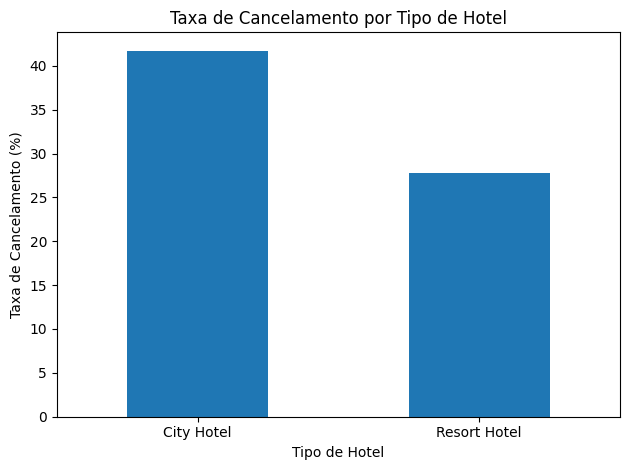

In [ ]:
import matplotlib.pyplot as plt

cancelamento_por_hotel.plot(kind="bar")

plt.title("Taxa de Cancelamento por Tipo de Hotel")
plt.xlabel("Tipo de Hotel")
plt.ylabel("Taxa de Cancelamento (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [ ]:
cancelamento_segmento = (
    df.groupby("market_segment")["is_canceled"]
      .mean()
      .mul(100)
      .round(2)
      .sort_values(ascending=False)
)

print("Taxa de cancelamento por segmento de mercado (%):")
print(cancelamento_segmento)

Taxa de cancelamento por segmento de mercado (%):
market_segment
Undefined        100.00
Groups            61.06
Online TA         36.72
Offline TA/TO     34.32
Aviation          21.94
Corporate         18.73
Direct            15.34
Complementary     13.06
Name: is_canceled, dtype: float64


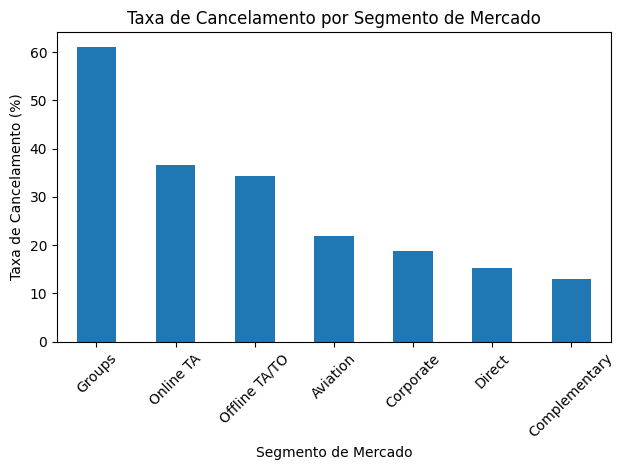

In [ ]:
segmentos_grafico = cancelamento_segmento.drop(
    "Undefined",
    errors="ignore"
)

segmentos_grafico.plot(kind="bar")

plt.title("Taxa de Cancelamento por Segmento de Mercado")
plt.xlabel("Segmento de Mercado")
plt.ylabel("Taxa de Cancelamento (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [ ]:
df["total_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

df["total_guests"] = (
    df["adults"] +
    df["children"] +
    df["babies"]
)

df["has_car_parking"] = (
    df["required_car_parking_spaces"] > 0
).astype(int)

df["has_previous_booking"] = (
    (
        df["previous_bookings_not_canceled"] +
        df["previous_cancellations"]
    ) > 0
).astype(int)

df[
    [
        "total_nights",
        "total_guests",
        "has_car_parking",
        "has_previous_booking"
    ]
].head()

,total_nights,total_guests,has_car_parking,has_previous_booking
0,0,2.0,0,0
1,0,2.0,0,0
2,1,1.0,0,0
3,1,1.0,0,0
4,2,2.0,0,0


In [ ]:
from sklearn.model_selection import train_test_split

features = [
    "hotel",
    "lead_time",
    "arrival_date_month",
    "market_segment",
    "distribution_channel",
    "deposit_type",
    "customer_type",
    "adr",
    "total_nights",
    "total_guests",
    "has_car_parking",
    "has_previous_booking"
]

X = df[features]
y = df["is_canceled"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dados de treino:", X_train.shape)
print("Dados de teste:", X_test.shape)

Dados de treino: (95512, 12)
Dados de teste: (23878, 12)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Separar colunas numéricas e categóricas
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numeric_features = X.select_dtypes(exclude=["object"]).columns.tolist()

# Tratamento das variáveis numéricas
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Tratamento das variáveis categóricas
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Juntar os tratamentos
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Variáveis numéricas:")
print(numeric_features)

print("\nVariáveis categóricas:")
print(categorical_features)

Variáveis numéricas:
['lead_time', 'adr', 'total_nights', 'total_guests', 'has_car_parking', 'has_previous_booking']

Variáveis categóricas:
['hotel', 'arrival_date_month', 'market_segment', 'distribution_channel', 'deposit_type', 'customer_type']


In [ ]:
# Criar o modelo Random Forest
modelo = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Treinar o modelo
modelo.fit(X_train, y_train)

print("Modelo Random Forest treinado com sucesso!")

Modelo Random Forest treinado com sucesso!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Fazer previsões com os dados de teste
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

# Calcular métricas
acuracia = accuracy_score(y_test, y_pred)
precisao = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Resultados do modelo:")
print("Acurácia:", round(acuracia, 4))
print("Precisão:", round(precisao, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))

Resultados do modelo:
Acurácia: 0.8237
Precisão: 0.7871
Recall: 0.7184
F1-score: 0.7512
ROC-AUC: 0.8979


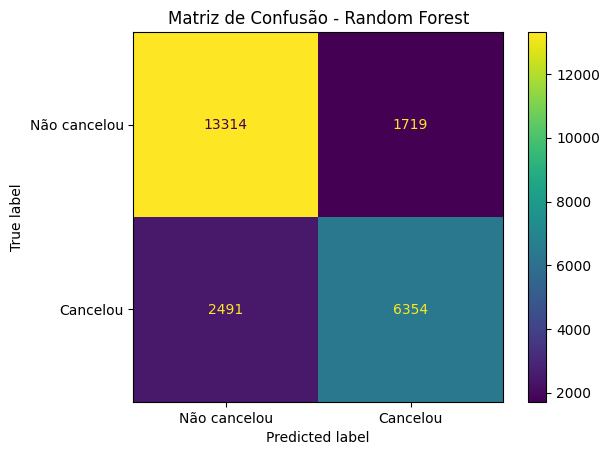

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matriz = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Não cancelou", "Cancelou"]
)

disp.plot()
plt.title("Matriz de Confusão - Random Forest")
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Recuperar os nomes das variáveis após o pré-processamento
nomes_variaveis = modelo.named_steps[
    "preprocessor"
].get_feature_names_out()

# Recuperar a importância calculada pelo Random Forest
importancias = modelo.named_steps[
    "classifier"
].feature_importances_

# Criar tabela
importancia_df = pd.DataFrame({
    "Variavel": nomes_variaveis,
    "Importancia": importancias
})

# Selecionar as 10 mais importantes
top10 = (
    importancia_df
    .sort_values("Importancia", ascending=False)
    .head(10)
)

print("10 variáveis mais importantes:")
print(top10)

10 variáveis mais importantes:
                        Variavel  Importancia
0                 num__lead_time     0.280503
1                       num__adr     0.218630
33  cat__deposit_type_No Deposit     0.101772
34  cat__deposit_type_Non Refund     0.089458
2              num__total_nights     0.075676
5      num__has_previous_booking     0.027554
3              num__total_guests     0.025909
4           num__has_car_parking     0.025171
24    cat__market_segment_Groups     0.015134
38  cat__customer_type_Transient     0.015072


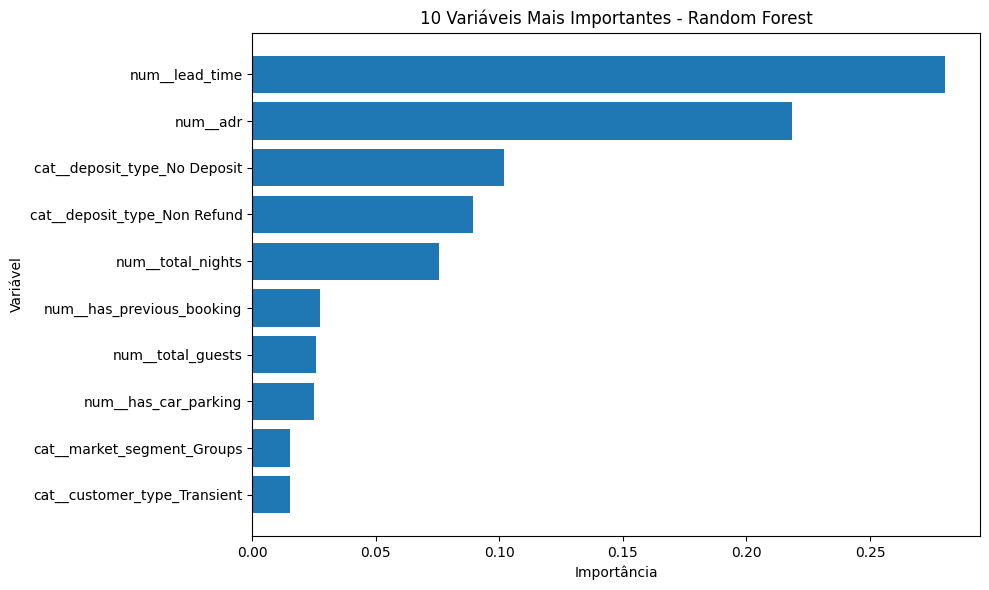

In [ ]:
top10_grafico = top10.sort_values("Importancia")

plt.figure(figsize=(10, 6))

plt.barh(
    top10_grafico["Variavel"],
    top10_grafico["Importancia"]
)

plt.title("10 Variáveis Mais Importantes - Random Forest")
plt.xlabel("Importância")
plt.ylabel("Variável")

plt.tight_layout()
plt.show()

In [ ]:
# Criar faixas de antecedência da reserva
df["faixa_lead_time"] = pd.cut(
    df["lead_time"],
    bins=[-1, 30, 90, 180, 365, float("inf")],
    labels=[
        "0-30 dias",
        "31-90 dias",
        "91-180 dias",
        "181-365 dias",
        "Mais de 365 dias"
    ]
)

# Calcular taxa de cancelamento por faixa
cancelamento_lead_time = (
    df.groupby("faixa_lead_time", observed=True)["is_canceled"]
    .mean()
    .mul(100)
    .round(2)
)

print("Taxa de cancelamento por antecedência da reserva (%):")
print(cancelamento_lead_time)

Taxa de cancelamento por antecedência da reserva (%):
faixa_lead_time
0-30 dias           18.56
31-90 dias          37.70
91-180 dias         44.71
181-365 dias        55.45
Mais de 365 dias    67.66
Name: is_canceled, dtype: float64


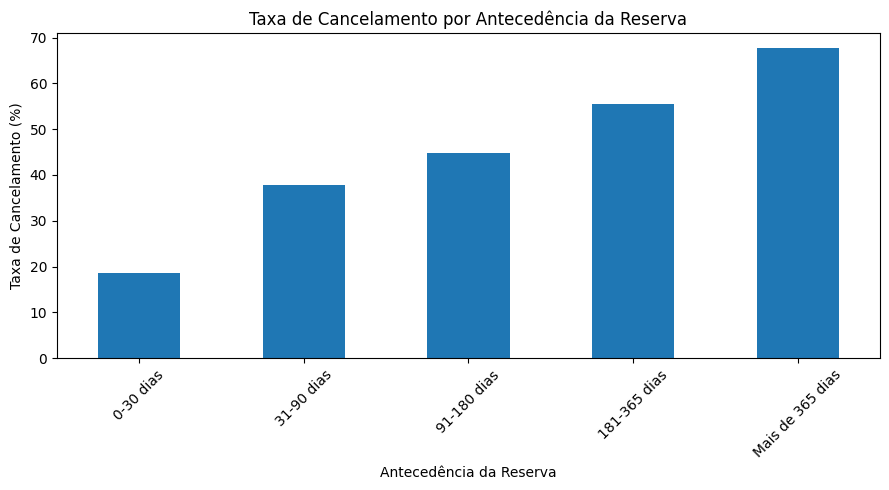

In [ ]:
import matplotlib.pyplot as plt

cancelamento_lead_time.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Taxa de Cancelamento por Antecedência da Reserva")
plt.xlabel("Antecedência da Reserva")
plt.ylabel("Taxa de Cancelamento (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Análise: Os resultados demonstram uma relação entre a antecedência da reserva e a taxa de cancelamento. Reservas realizadas com até 30 dias de antecedência apresentam menor percentual de cancelamento, enquanto reservas realizadas com maior antecedência possuem taxas progressivamente maiores. Esse resultado indica que o tempo de antecedência da reserva (lead_time) é uma variável relevante para identificar o risco de cancelamento.

Conclusão

A análise dos dados de reservas de hotéis permitiu identificar fatores relacionados ao cancelamento de reservas. Foi observado que reservas realizadas com maior antecedência apresentam taxas de cancelamento mais elevadas.

O modelo Random Forest apresentou acurácia de 82,37% e ROC-AUC de 0,8979, demonstrando boa capacidade para diferenciar reservas com maior e menor probabilidade de cancelamento.

Entre as variáveis de maior importância para o modelo destacaram-se o tempo de antecedência da reserva (lead_time), a diária média (adr), o tipo de depósito e a quantidade total de noites.

Os resultados mostram que técnicas de análise de dados e aprendizado de máquina podem auxiliar hotéis na identificação antecipada de reservas com maior risco de cancelamento, contribuindo para o planejamento e a tomada de decisões.

In [ ]:
from sklearn.metrics import classification_report

print("Relatório de Classificação:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Não cancelou", "Cancelou"]
    )
)

Relatório de Classificação:
              precision    recall  f1-score   support

Não cancelou       0.84      0.89      0.86     15033
    Cancelou       0.79      0.72      0.75      8845

    accuracy                           0.82     23878
   macro avg       0.81      0.80      0.81     23878
weighted avg       0.82      0.82      0.82     23878

